In [9]:
import importlib
importlib.reload(importlib.import_module('RelaxationMover_RFM'))
from RelaxationMover_RFM import *

device = "cuda:3" if torch.cuda.is_available() else "cpu"
print(device)
torch.set_default_device(device)
torch.set_default_dtype(torch.float64)
if device == "cpu":
    torch.set_num_threads(4)

seed = 42
torch.cuda.empty_cache()
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
rand_gen = torch.Generator(device=device)
rand_gen.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

import numpy as np
np.random.seed(seed)

cuda:3


In [10]:
def unit_square_mesh(steps = 50, quad=True):
    x = torch.linspace(0, 1, steps + 1)
    y = torch.linspace(0, 1, steps + 1)
    x = x.repeat(steps + 1)
    y = y.repeat_interleave(steps + 1)
    V = torch.stack([x, y], dim=1)

    T = []
    if quad == False:
        for i in range(steps):
            for j in range(steps):
                T.append([j * (steps + 1) + i, j * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i + 1])
                T.append([j * (steps + 1) + i, (j + 1) * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i])
    else:
        for i in range(steps):
            for j in range(steps):
                T.append([j * (steps + 1) + i, j * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i])
    T = torch.tensor(T, dtype=torch.long)

    return V, T

In [11]:
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import matplotlib.gridspec as gridspec

def draw_quad_mesh(V, T, ax=None, linewidth=0.3):
    if ax is None:
        _, ax = plt.subplots()
    verts = V[T].cpu().numpy()
    polyc = PolyCollection(verts, edgecolors='k', linewidths=linewidth, facecolors='none')
    ax.add_collection(polyc)
    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')

Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate_stagnation), best CV: (109, 1.70255813e-01), best relative move rate: (266, 1.21083381e-08), run time: 4.49s
Offline time: 0.38 seconds, Online time: 4.49 seconds
CV residual: 1.70e-01


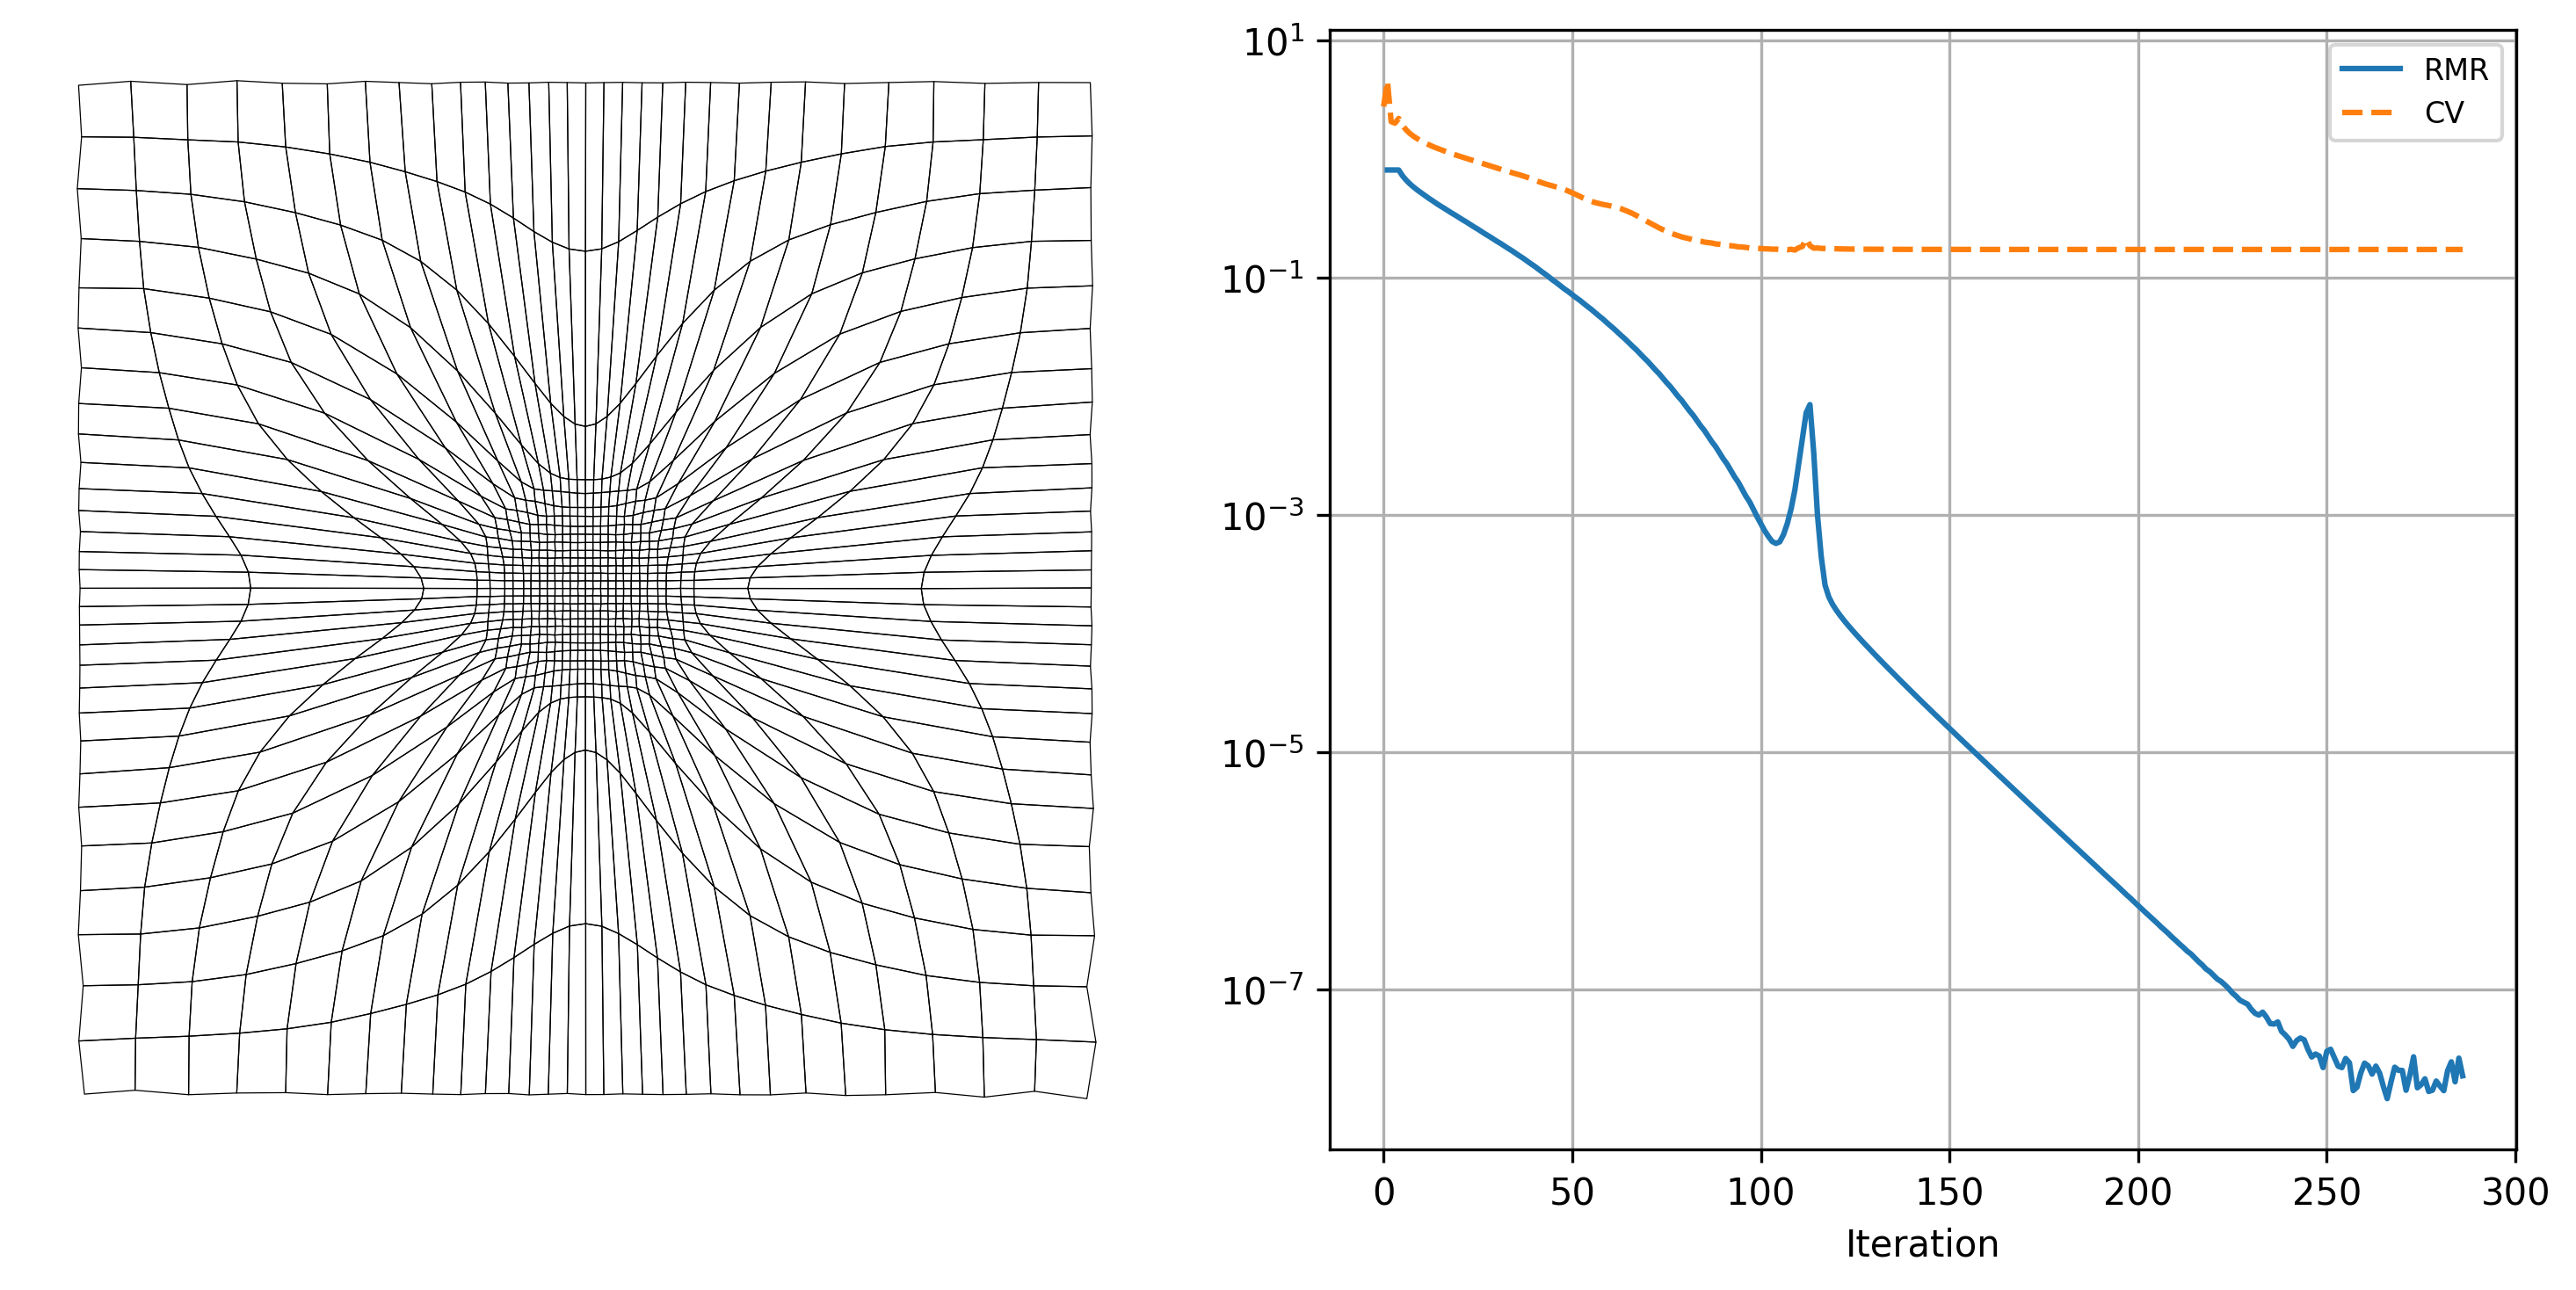

In [ ]:
def monitor_bell(X):
    a = 0
    alpha1 = 50
    alpha2 = 100
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])
rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=1,
                    n_hidden=1500,  gamma=2.0, n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=1e-8)

it_cfg = IterationConfig(maxiter=600, rtol=1e-8, pseudo_dt=0.1, early_stop_num=20, verbose=False)

mover = RelaxationMover_RFM(domain, rfm_cfg)
mover.relaxation(monitor_bell, it_cfg)
print(f'Offline time: {mover.build_time:.2f} seconds, Online time: {mover.run_time:.2f} seconds')
print(f'CV residual: {mover.best_CV_residual:.2e}')

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

V, T = unit_square_mesh(30, quad=True)
adapt_V = mover.move(V)
draw_quad_mesh(adapt_V, T, ax=ax[0])

ax[1].semilogy(mover.relative_move_rate_record, label="RMR")
ax[1].semilogy(mover.CV_residual_record, "--", label="CV")
ax[1].legend(fontsize=8)
ax[1].set_xlabel("Iteration")
ax[1].grid(True)

plt.tight_layout()
plt.savefig('bell_without_boundary_penalty.pdf', bbox_inches='tight')
plt.show()
plt.close()

del mover

Decomposing the problem size of A:  torch.Size([10401, 1500]) with solver QR
Stopped (relative_move_rate_stagnation), best CV: (141, 1.14232044e-01), best relative move rate: (136, 3.16976378e-03), run time: 2.18s
Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate), best CV: (108, 1.70244120e-01), best relative move rate: (272, 8.07669333e-09), run time: 4.27s
Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate_stagnation), best CV: (234, 1.26751551e-01), best relative move rate: (214, 3.83666760e-07), run time: 3.68s
Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate_stagnation), best CV: (163, 1.20600146e-01), best relative move rate: (143, 5.25961035e-05), run time: 2.56s
Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate_stagnation), best CV: (120, 1.15396061e-01), best 

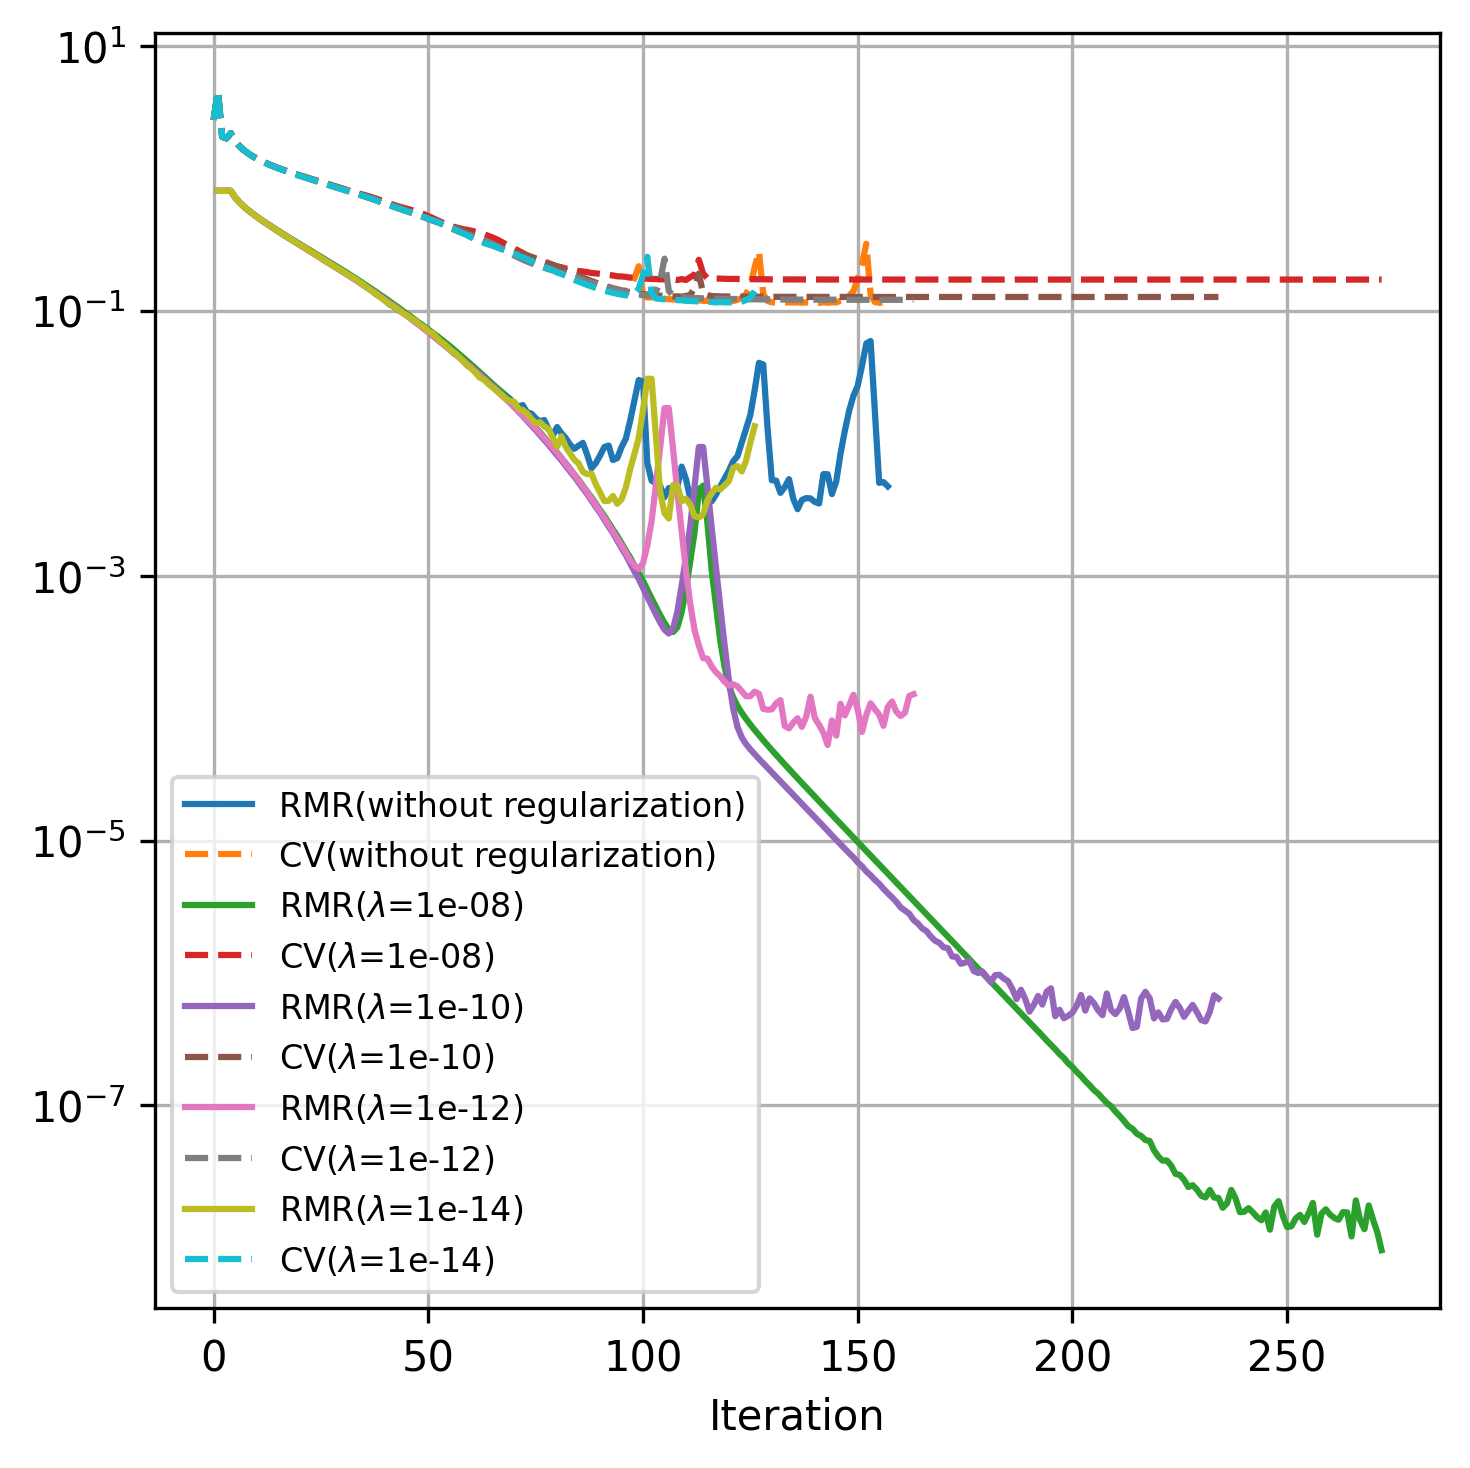

In [13]:
def monitor_bell(X):
    a = 0
    alpha1 = 50
    alpha2 = 100
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])

fig, ax = plt.subplots(1, 1, figsize=(5, 5), dpi=300)
damp_values = [0, 1e-8, 1e-10, 1e-12, 1e-14]
#damp_values = [0]

for i, damp_value in enumerate(damp_values):
    rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=100,
                        n_hidden=1500,  gamma=2.0, n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=damp_value)
    it_cfg = IterationConfig(maxiter=500, rtol=1e-8, pseudo_dt=0.1, early_stop_num=20, verbose=False)
    mover = RelaxationMover_RFM(domain, rfm_cfg)
    mover.relaxation(monitor_bell, it_cfg)
    if i == 0:
        # V, T = unit_square_mesh(30, quad=True)
        # adapt_V = mover.move(V)
        # draw_quad_mesh(adapt_V, T, ax=ax[0])
        ax.semilogy(mover.relative_move_rate_record, label=f"RMR(without regularization)")
        ax.semilogy(mover.CV_residual_record, "--", label=f"CV(without regularization)")
    else:
        ax.semilogy(mover.relative_move_rate_record, label=rf"RMR($\lambda$={damp_value:.0e})")
        ax.semilogy(mover.CV_residual_record, "--", label=rf"CV($\lambda$={damp_value:.0e})")
    del mover

ax.legend(fontsize=8)
ax.set_xlabel("Iteration")
ax.grid(True)

plt.tight_layout()
plt.savefig('bell_with_different_damp_value.pdf', bbox_inches='tight')
plt.show()
plt.close()

Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate), best CV: (107, 1.70244120e-01), best relative move rate: (271, 8.07669333e-09), run time: 4.25s
Stopped (relative_move_rate_stagnation), best CV: (597, 1.81558957e-01), best relative move rate: (577, 1.29775179e-08), run time: 9.29s


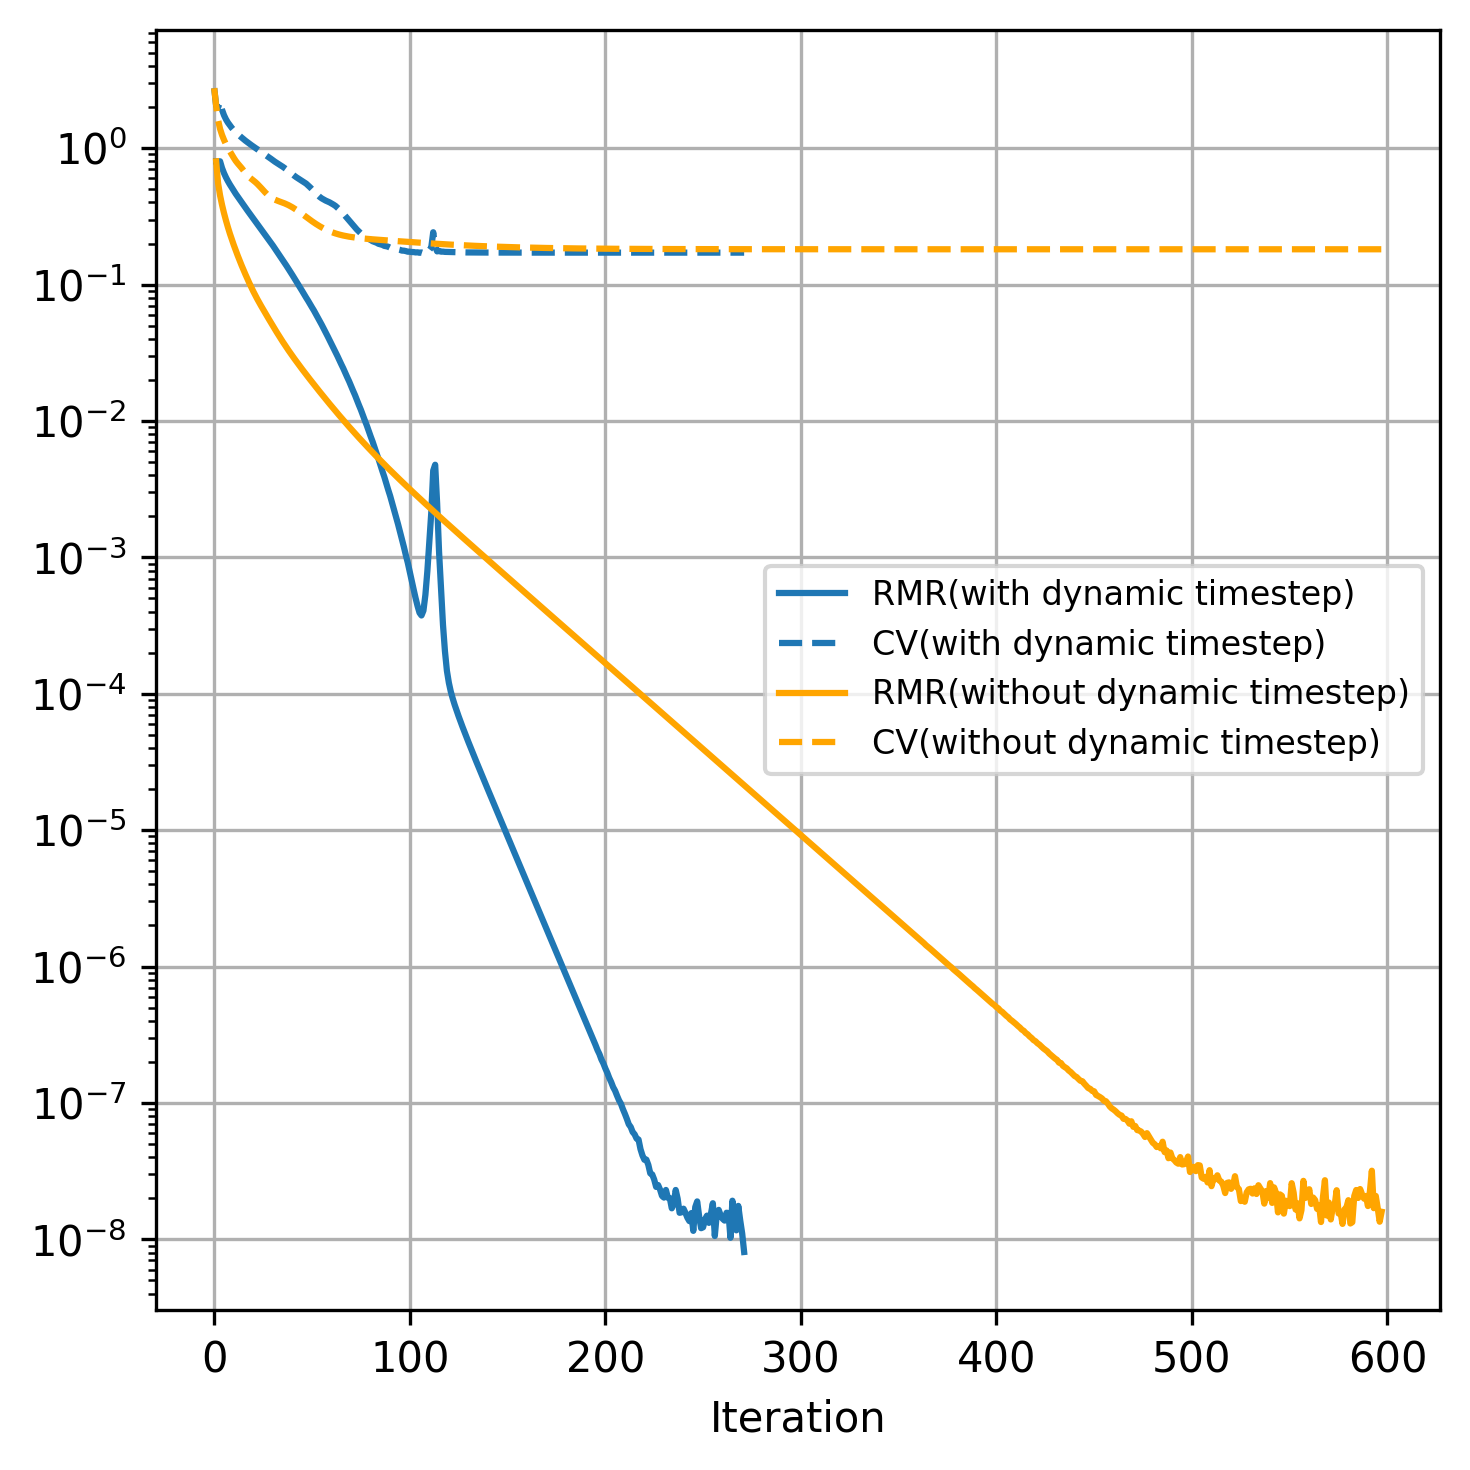

In [14]:
def monitor_bell(X):
    a = 0
    alpha1 = 50
    alpha2 = 100
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])

fig, ax = plt.subplots(1, 1, figsize=(5, 5), dpi=300)

rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=100,
                    n_hidden=1500,  gamma=2.0, n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=1e-8)
it_cfg = IterationConfig(maxiter=1000, rtol=1e-8, pseudo_dt=0.05, early_stop_num=20, verbose=False)

mover = RelaxationMover_RFM(domain, rfm_cfg)
mover.relaxation(monitor_bell, it_cfg)
ax.semilogy(mover.relative_move_rate_record, label=f"RMR(with dynamic timestep)", color='tab:blue')
ax.semilogy(mover.CV_residual_record, "--", label=f"CV(with dynamic timestep)", color='tab:blue')

it_cfg.adaptive_dt = False
mover.relaxation(monitor_bell, it_cfg)
ax.semilogy(mover.relative_move_rate_record, label=f"RMR(without dynamic timestep)", color='orange')
ax.semilogy(mover.CV_residual_record, "--", label=f"CV(without dynamic timestep)", color='orange')

ax.legend(fontsize=8)
ax.set_xlabel("Iteration")
ax.grid(True)

plt.tight_layout()
plt.savefig('bell_adapt_dt.pdf', bbox_inches='tight')
plt.show()
plt.close()

del mover

Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Stopped (min_pseudo_dt), best CV: (104, 5.13325697e-01), best relative move rate: (104, 3.00490496e-02), run time: 1.17s
tanh, damp=1e-08: CV=5.133e-01, RMR=3.005e-02, stop=min_pseudo_dt
Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Stopped (relative_move_rate), best CV: (162, 1.42102665e-01), best relative move rate: (162, 9.51322457e-09), run time: 1.70s
tanh3, damp=1e-08: CV=1.421e-01, RMR=9.513e-09, stop=relative_move_rate
Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Stopped (maxiter), best CV: (299, 1.42001984e-01), best relative move rate: (272, 1.70394343e-07), run time: 3.15s
tanh, damp=1e-10: CV=1.420e-01, RMR=1.704e-07, stop=maxiter
Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Stopped (maxiter), best CV: (257, 1.15945934e-01), best relative move rate: (149, 5.87588435e-08), run time: 3.14s
tanh3, damp=1e-10

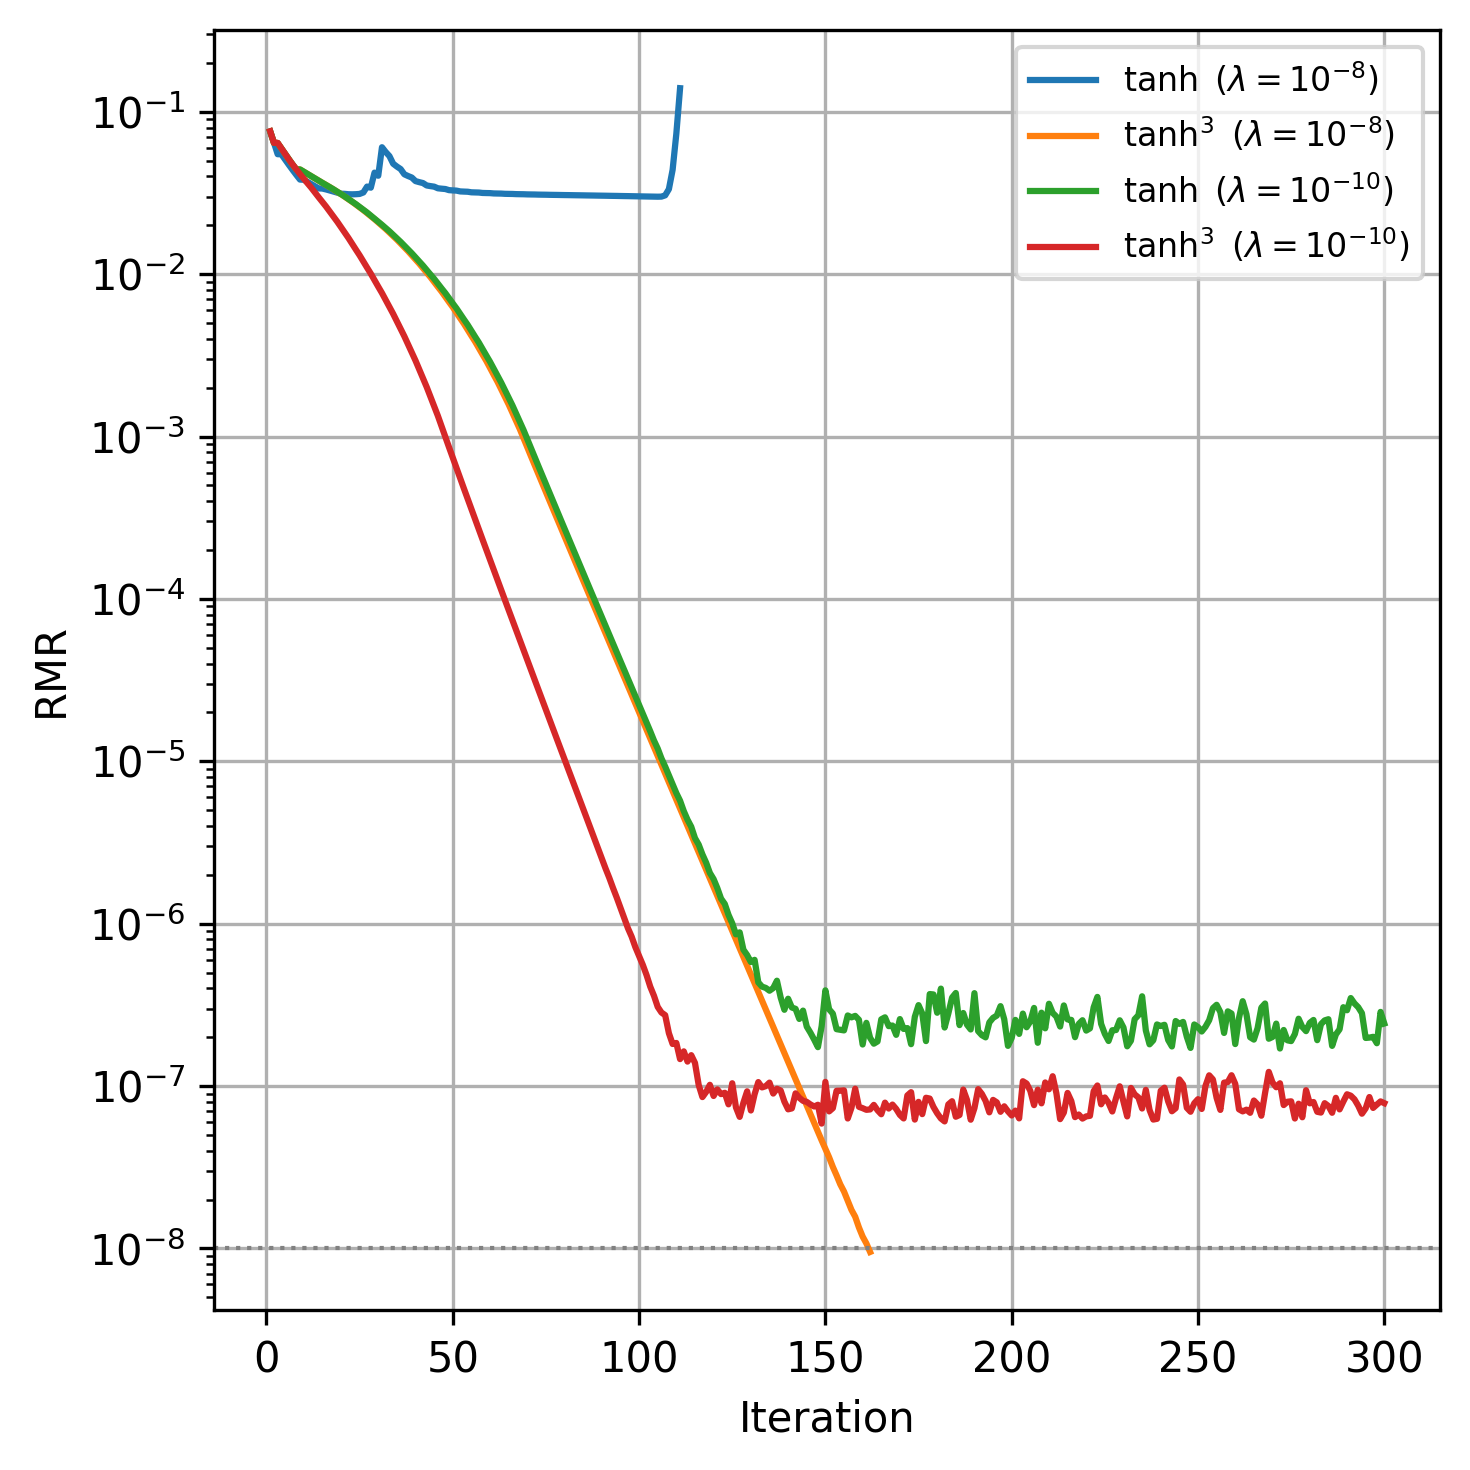

In [15]:
def monitor_ring(X):
    a = 0.25
    alpha1 = 10
    alpha2 = 200
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])
damp_values = [1e-8, 1e-10]

# Activation comparison with the TransNet-inspired construction enabled.
fig, ax = plt.subplots(1, 1, figsize=(5, 5), dpi=300)
for damp_value in damp_values:
    for rf, rf_label in zip(['tanh', 'tanh3'], [r'$\tanh$', r'$\tanh^3$']):
        rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400,
                            corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=100,
                            n_hidden=1000, gamma=2.0, n_subdomains=1, pou='PsiA',
                            rf=rf, damp_value=damp_value, seed=100)
        it_cfg = IterationConfig(maxiter=300, rtol=1e-8, pseudo_dt=0.1,
                                 early_stop_num=301, verbose=False, adaptive_dt=True)
        mover = RelaxationMover_RFM(domain, rfm_cfg)
        mover.relaxation(monitor_ring, it_cfg)
        label = rf_label + r' ($\lambda=10^{%d}$)' % int(np.log10(damp_value))
        ax.semilogy(mover.relative_move_rate_record, label=label)
        cv = mover.CV_residual_record[mover.best_relative_move_rate_iteration]
        print(f'{rf}, damp={damp_value:.0e}: CV={cv:.3e}, '
              f'RMR={mover.best_relative_move_rate:.3e}, stop={mover.stop_reason}')
        del mover

ax.axhline(it_cfg.rtol, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('Iteration')
ax.set_ylabel('RMR')
ax.legend(fontsize=8)
ax.grid(True)
plt.tight_layout()
plt.savefig('ring_activation_comparison.pdf', bbox_inches='tight')
plt.show()
plt.close()
